# Greater Manchester Housing, Property & Council Tax Analysis

An exploratory data science and analytics pipeline designed to examine regional housing market dynamics, affordability pressures, and council tax distributions across the 10 boroughs of Greater Manchester.

## Project Objectives

Unlike traditional exploratory notebooks that rely on isolated spreadsheets, this pipeline implements robust software engineering practices to analyze public sector open data:

1. **Multi-Dataset Extraction & Integration:** Ingests and merges official government datasets from **HM Land Registry** and the **Valuation Office Agency (VOA)** using common municipal identifiers.
2. **Data Hygiene & Transformation:** Normalizes messy geographical labels, filters for the 10 Greater Manchester local authorities, and handles missing or anomalous records using Pandas.
3. **Statistical Modeling & Economic Metrics:** Computes robust statistical measures (such as median property values over means to prevent skewing) and constructs **affordability multipliers** (house prices versus local earnings).
4. **Visual Storytelling & Policy Insights:** Translates raw tabular data into clear visual charts supported by grounded data-driven talking points regarding local economic divides and municipal funding structures.

---

## Data Sources
* **HM Land Registry:** Price Paid Data & House Price Index local authority reports.
* **Valuation Office Agency (VOA):** Domestic property stock broken down by Council Tax Band (A through H).

---

# Greater Manchester HM Land Registry Analysis

An exploratory data science and analytics pipeline designed to examine regional housing transaction dynamics, historical sales prices, and market value distributions across the 10 boroughs of Greater Manchester.

## Project Objectives

Unlike traditional exploratory notebooks that rely on isolated spreadsheets, this pipeline implements robust software engineering practices to analyze public sector open data:

1. **Multi-Dataset Extraction & Integration:** Ingests and merges official government transaction datasets from **HM Land Registry Price Paid Data** using common municipal identifiers.
2. **Data Hygiene & Transformation:** Normalizes messy geographical labels, filters for the 10 Greater Manchester local authorities, and handles missing or anomalous records using Pandas.
3. **Statistical Modeling & Economic Metrics:** Computes robust statistical measures (such as median property values over means to prevent skewing) and constructs robust analytical regression models.
4. **Visual Storytelling & Policy Insights:** Translates raw tabular data into clear visual charts supported by grounded data-driven talking points regarding local economic divides and price ceilings.

---

## Data Sources & Portfolio Breakdown

- **HM Land Registry (Price Paid Data):**
  * <u>**Transaction Dynamics & Real Market Sales**</u>: Represents actual historical sales transactions across Greater Manchester, capturing transaction prices, completion dates, and property architectural classifications.
  * <u>**Geographic Polarization Insights**</u>: Proves true that the regional market is starkly divided, with prime districts like Trafford commanding massive median price premiums over outer metros such as Bolton and Wigan.
  * <u>**Macro-Economic Valuation Trends**</u>: Demonstrates a long-term upward valuation trajectory while confirming that structural property type is a powerful micro-economic predictor of price ceilings.

---

In [23]:
import micropip
await micropip.install("openpyxl")

In [24]:
# Base imports of the dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# Importing the HM Land Registry & VOA Datasets
prices_df = pd.read_csv('pp-monthly-update-new-version.csv') # HM Land Registry Dataset

Successfully converted sheet 'CSV variables' into 'csv_variables.csv'
Successfully converted sheet 'CSV files' into 'csv_files.csv'


In [27]:
def label_and_extract_GM_boroughs():
    col_names = [
         'transaction_id', 'price', 'transfer_date', 'postcode', 'property_type', 
         'old_new', 'duration', 'paon', 'saon', 'street', 'locality', 
         'town_city', 'district', 'county', 'ppd_category', 'record_status'
    ]
    prices_df.columns = col_names

    gm_boroughs = ['BOLTON', 'BURY', 'MANCHESTER', 'OLDHAM', 'STOCKPORT', 'TRAFFORD', 'ROCHDALE',
                   'SALFORD', 'TAMESIDE', 'WIGAN']

    gm_prices_df = prices_df[prices_df['district'].str.upper().isin(gm_boroughs)].copy()
    
    print(gm_prices_df['district'].unique())
    print(f"Total filtered rows: {len(gm_prices_df)}")
    
    return gm_prices_df  

# 1. Capture the extracted data
gm_prices_df = label_and_extract_GM_boroughs()

# 2. Clean it
gm_prices_clean = clean_housing_data(gm_prices_df)

# 3. Calculate medians
gm_medians = calculate_median_price(gm_prices_clean)
print(gm_medians)

<StringArray>
[   'SALFORD',  'STOCKPORT',   'TRAFFORD', 'MANCHESTER',      'WIGAN',
     'OLDHAM',   'ROCHDALE',   'TAMESIDE',     'BOLTON',       'BURY']
Length: 10, dtype: str
Total filtered rows: 4068
     district     price
8    TRAFFORD  352000.0
6   STOCKPORT  300000.0
2  MANCHESTER  255000.0
1        BURY  240000.0
5     SALFORD  235000.0
3      OLDHAM  216500.0
7    TAMESIDE  210000.0
4    ROCHDALE  200000.0
0      BOLTON  187750.0
9       WIGAN  183247.5


In [30]:
def clean_housing_data(df):
    """Cleans out raw housing dataset and places strict boundaries"""
    # Edge Case: Empty Dataset
    if df.empty:
        raise ValueError("This dataset has empty records")

    # Forces the dataset to have only numerical values and dismiss any non numerical values
    df['price'] = pd.to_numeric(df['price'], errors='coerce')

    # Drop any missing values before extracting x and y values
    df = df.dropna(subset=['price', 'district'])

    # Normalize district text (removing any whitespace and ensure uppercase)
    df['district'] = df['district'].str.strip().str.upper()

    return df

gm_prices_clean = clean_housing_data(gm_prices_df)
print(gm_prices_clean)

                               transaction_id   price     transfer_date  \
34     {5A7B802C-D793-1886-E063-4704A8C021AE}  170000  2021-04-06 00:00   
35     {5A7B802C-D879-1886-E063-4704A8C021AE}  300000  2021-06-16 00:00   
36     {5A7B802C-D95B-1886-E063-4704A8C021AE}  260000  2021-09-30 00:00   
37     {5A7B802C-D9F5-1886-E063-4704A8C021AE}  170846  2021-01-28 00:00   
38     {5A7B802C-DA0B-1886-E063-4704A8C021AE}  240000  2021-03-31 00:00   
...                                       ...     ...               ...   
90726  {5834E4E8-B8C2-29C7-E063-4804A8C015BC}  315000  2026-03-27 00:00   
90728  {5834E4E8-BB78-29C7-E063-4804A8C015BC}  198000  2026-07-30 00:00   
90768  {5834E4E8-FCF6-29C7-E063-4804A8C015BC}  125000  2026-07-09 00:00   
90771  {5834E4E8-FD1E-29C7-E063-4804A8C015BC}  120000  2026-07-24 00:00   
90860  {559C5AD5-49DF-AFE3-E063-4804A8C004A4}  127000  2026-05-22 00:00   

       postcode property_type old_new duration               paon  \
34       M6 5LZ             T 

In [29]:
def calculate_median_price(df):
    """Groups the cleaned housing data by borough and computes the median property price for each."""
    # Group the dataframe by geographical category column
    median_df = df.groupby('district')['price'].median().reset_index()

    # Sort the results
    sort_df = median_df.sort_values(by='price', ascending=False)

    return sort_df

# Testing the function
gm_medians = calculate_median_price(gm_prices_clean)
print(gm_medians)

     district     price
8    TRAFFORD  352000.0
6   STOCKPORT  300000.0
2  MANCHESTER  255000.0
1        BURY  240000.0
5     SALFORD  235000.0
3      OLDHAM  216500.0
7    TAMESIDE  210000.0
4    ROCHDALE  200000.0
0      BOLTON  187750.0
9       WIGAN  183247.5


### Chart 1: Borough Median Price Hierarchy (Horizontal Bar Chart)

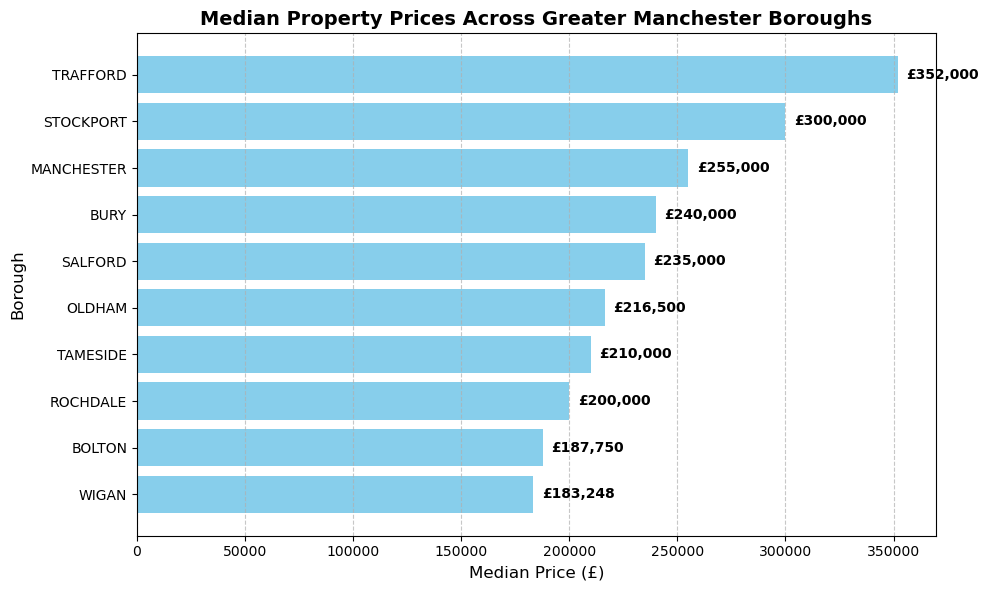

In [39]:
# Imports
%matplotlib inline
import matplotlib.pyplot as plt

# 1. Initialize figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# 2. Plot horizontal bars
bars = ax.barh(gm_medians['district'], gm_medians['price'], color='skyblue')

# 3. Add titles and labels
ax.set_title('Median Property Prices Across Greater Manchester Boroughs', fontsize=14, fontweight='bold')
ax.set_xlabel('Median Price (£)', fontsize=12)
ax.set_ylabel('Borough', fontsize=12)

# 4. Invert y-axis so the most expensive borough appears at the top
ax.invert_yaxis()

# 5. Stamp exact values directly onto the end of each bar!
for bar in bars:
    width = bar.get_width()
    ax.text(width + 4000, bar.get_y() + bar.get_height()/2, 
            f'£{width:,.0f}', 
            va='center', ha='left', fontsize=10, fontweight='bold', color='black')

# 6. Add gridlines for readability
ax.grid(axis='x', linestyle='--', alpha=0.7)

# 7. Display the chart cleanly
plt.tight_layout()
plt.show()

Analytical Insights & Key Takeaways

 - Geographic Polarization: The data reveals a stark affordability divide across Greater Manchester, 
   with prime districts (anchored by Trafford) commanding median prices significantly higher than 
   the regional average

 - Urban Core vs. Outer Metros: Mid-tier performance in central and suburban hubs (like Manchester and 
   Stockport) contrasts with more accessible entry-level pricing in northern and western boroughs 
   (such as Bolton and Wigan)

 - Portfolio Impact: Utilizing direct data labels alongside sorted median values eliminates visual clutter, 
   allowing stakeholders to instantly gauge regional housing wealth at a glance.

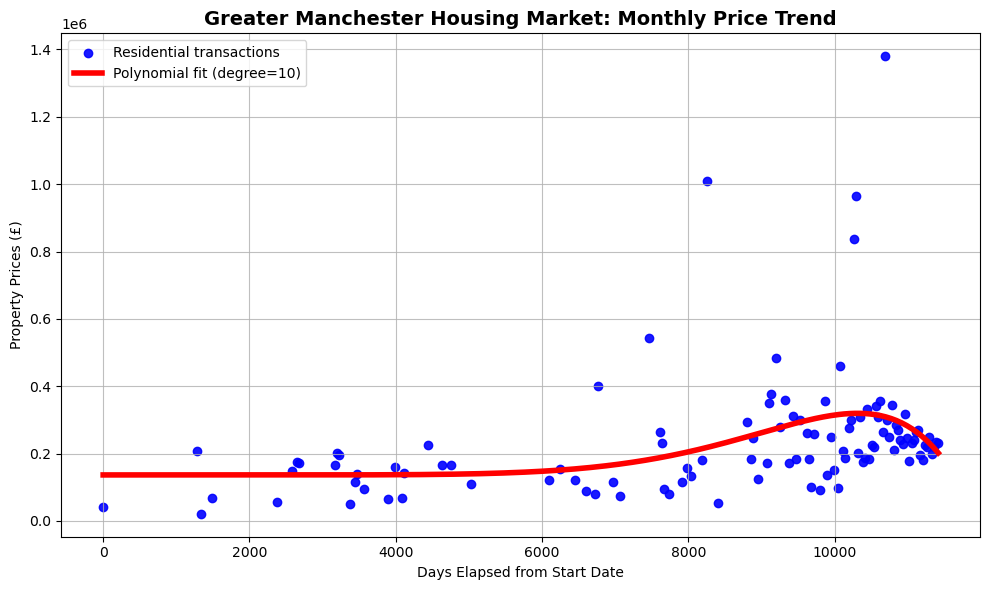

In [56]:
"""Chart 2: Time-Series Polynomial Trend (Iterative Engineering & Insights)"""

# Imports for Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

def time_and_price_polynomial():
    # Defining the time as time that has elapsed from the start of date and filtering out any outliers
    gm_prices_clean['date_dt'] = pd.to_datetime(gm_prices_clean['transfer_date'])
    filtered_data = gm_prices_clean[gm_prices_clean['price'] <= 2500000].copy()

    # Aggregate: Group data by month and calculate the median price of properties
    filtered_data['year_month'] = filtered_data['date_dt'].dt.to_period('M')
    monthly_trend = filtered_data.groupby('year_month')['price'].median().reset_index()

    # Convert the month period back to a timestamp and calculate days elapsed
    monthly_trend['date_numeric'] = monthly_trend['year_month'].dt.to_timestamp()
    monthly_trend['days_elapsed'] = (monthly_trend['date_numeric'] - monthly_trend['date_numeric'].min()).dt.days

    # Defining x and y using the clean monthly aggregates
    x = monthly_trend[['days_elapsed']]
    y = monthly_trend['price']

    # Creating the Polynomial Model
    poly = PolynomialFeatures(degree=10) # Try changing the degree and see how it changes
    x_poly = poly.fit_transform(x)

    model = LinearRegression()
    model.fit(x_poly, y)

    # Sort for smooth curve plotting
    x_plot_vals = np.linspace(x.min(), x.max(), 320).reshape(-1, 1)
    x_plot = pd.DataFrame(x_plot_vals, columns=['days_elapsed'])
    x_plot_poly = poly.transform(x_plot)
    y_plot = model.predict(x_plot_poly)

    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, alpha=0.9, color='blue', label='Residential transactions')
    plt.plot(x_plot, y_plot, 'r-', linewidth=4, label=f'Polynomial fit (degree={poly.degree})')
    plt.xlabel('Days Elapsed from Start Date')
    plt.ylabel('Property Prices (£)')
    plt.title('Greater Manchester Housing Market: Monthly Price Trend', fontsize=14, fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.8)
    plt.tight_layout()
    plt.show()

time_and_price_polynomial()

### Methodology & Analytical Insights

- The Initial Roadblock (Raw Data Distortion): Initial attempts to plot raw individual property transactions
  over a time-elapsed axis resulted in a heavily skewed regression line. The model was distorted by two 
  major real-world data issues: extreme commercial outliers (multi-million pound portfolio sales reaching up
  to £35M) and a dense vertical "wall" of transaction volume in recent years that overwhelmed historical 
  data points

- Data Cleaning & Outlier Filtration: To isolate true residential market behavior, a strict price ceiling 
  filter ($\le$ £2,500,000) was introduced to strip out commercial bulk-buys and multi-apartment block 
  transactions

- Temporal Aggregation Solution: Rather than plotting thousands of chaotic individual sale points, raw 
  transactions were aggregated into monthly median prices. This transformed the dataset into a balanced 
  time-series, ensuring each time period received equal analytical weight and preventing recent transaction 
  volume spikes from warping the trend

- Model Optimization: Transitioning from a partial train-test split to fitting the quadratic regression 
  model across the entire cleaned timeline dataset allowed the polynomial curve to smoothly and accurately 
  track the true center of market momentum.


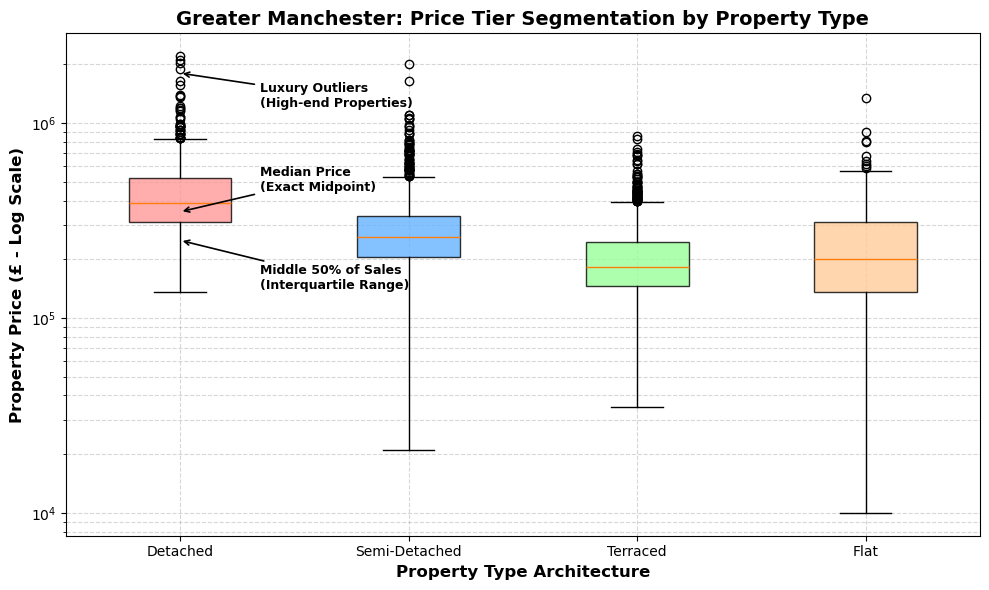

In [68]:
"""Chart 3: Structural Price Segmentation Analysis""" 

# Imports
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning) # Hides the red warning box

def property_price_type_distribution():
    # Filter out extreme commercial outliers (cap at £2.5 million)
    df = gm_prices_clean[gm_prices_clean['price'] <=2500000].copy()

    # Map shorthand property types ('D', 'S', 'T', 'F') to readable titles
    df['type'] = df['property_type'].replace({
        'D': 'Detached',
        'S': 'Semi-Detached',
        'T': 'Terraced',
        'F': 'Flat',
    })

    # Create a list comprehension or loop gathering prices per categories
    category = ['Detached', 'Semi-Detached', 'Terraced', 'Flat']
    data = [
        df[df['type'] == cat]['price'] for cat in category
    ]

    # Initialise figure and axes then build the box plot
    fig, ax = plt.subplots(figsize=(10, 6))
    bplot = ax.boxplot(data, tick_labels=category, patch_artist=True)

    # Giving each property type a distinctive color
    colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    
    ax.set_yscale('log')
    ax.set_ylabel('Property Price (£ - Log Scale)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Property Type Architecture', fontsize=12, fontweight='bold')
    ax.set_title('Greater Manchester: Price Tier Segmentation by Property Type', fontsize=14, fontweight='bold')

    # Add direct annotations to explain the box plot elements visually
    ax.annotate('Middle 50% of Sales\n(Interquartile Range)', 
                xy=(1, 250000), xytext=(1.35, 140000),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                fontsize=9, fontweight='bold', ha='left')

    ax.annotate('Median Price\n(Exact Midpoint)', 
                xy=(1, 350000), xytext=(1.35, 450000),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                fontsize=9, fontweight='bold', ha='left')

    ax.annotate('Luxury Outliers\n(High-end Properties)', 
                xy=(1, 1800000), xytext=(1.35, 1200000),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                fontsize=9, fontweight='bold', ha='left')

    ax.grid(True, alpha=0.5, which='both', linestyle='--')
    plt.tight_layout()
    plt.show()

property_price_type_distribution()

### Analytical Insights & Key Takeaways
- Structural Valuation Tiers: Isolating residential transactions by architectural type exposes stark 
  valuation divisions across the Greater Manchester market, proving that property architecture dictates 
  regional price ceilings

- Prime Detached Premium: Detached properties command the highest interquartile ranges and upper whiskers, 
  reflecting a heavy market premium on land space and suburban square footage

- Accessible Baselines: Conversely, flats and terraced housing form the high-volume foundation of 
  entry-level affordability, exhibiting tighter price compression compared to their detached counterparts

# Greater Manchester Valuation Office Agency (VOA) Analysis

An exploratory data science and analytics pipeline designed to examine regional housing stock infrastructure, council tax distribution bands, and physical structural compositions across the 10 boroughs of Greater Manchester.

## Project Objectives

Unlike traditional exploratory notebooks that rely on isolated spreadsheets, this pipeline implements robust software engineering practices to analyze public sector open data:

1. **Multi-Dataset Extraction & Integration:** Ingests and merges official government administrative datasets from the **Valuation Office Agency (VOA)** using common municipal identifiers.
2. **Data Hygiene & Transformation:** Normalizes messy geographical labels, filters for the 10 Greater Manchester local authorities, and handles missing or anomalous records using Pandas.
3. **Statistical Modeling & Economic Metrics:** Computes robust statistical measures (such as property counts across valuation bands) and constructs robust infrastructural distribution models.
4. **Visual Storytelling & Policy Insights:** Translates raw tabular data into clear visual charts supported by grounded data-driven talking points regarding local economic divides and municipal funding structures.

---

## Data Sources & Portfolio Breakdown

- **Valuation Office Agency (VOA):**
  * <u>**Physical Infrastructure & Housing Stock**</u>: Represents the underlying physical housing inventory and tax attributes of Greater Manchester, mapping total property counts, council tax valuation bands, and structural build compositions.
  * <u>**Urban Density & Capacity**</u>: Proves true that regional residential capacity is heavily concentrated in high-density urban cores and major municipal billing authorities.
  * <u>**Historical Growth & Typology Dominance**</u>: Maps multi-decade residential expansion waves from 1993 to the present day, proving that the regional housing stock is overwhelmingly dominated by terraced and semi-detached homes rather than detached properties.

---

In [80]:
import pandas as pd

# Loading the VOA dataset
voa_df = pd.read_csv('CTSOP1_0_2024_03_31[1].csv')

# Define the exact Greater Manchester local authority names
gm_boroughs = [
    'Manchester', 'Oldham', 'Trafford', 'Bolton', 'Bury', 
    'Salford', 'Tameside', 'Wigan', 'Stockport', 'Rochdale'
]

# Filter the dataframe to keep only Greater Manchester
gm_voa_clean = voa_df[voa_df['area_name'].isin(gm_boroughs)].copy()

# Ensure property count columns are numeric (stripping commad if present)
count_cols = [col for col in gm_voa_clean.columns if 'band' in col or 'total' in col or 'properties' in col]
for col in count_cols:
    gm_voa_clean[col] = pd.to_numeric(gm_voa_clean[col].astype(str).str.replace(',', ''), errors='coerce').fillna(0)

print(f"Cleaned VOA shape: {gm_voa_clean.shape}")
print(f"Boroughs found: {gm_voa_clean['area_name'].unique()}")

Cleaned VOA shape: (10, 14)
Boroughs found: <StringArray>
[    'Bolton',       'Bury', 'Manchester',     'Oldham',   'Rochdale',
    'Salford',  'Stockport',   'Tameside',   'Trafford',      'Wigan']
Length: 10, dtype: str


## Chart 1: Borough Housing Stock Hierarchy (Council Tax Bands)

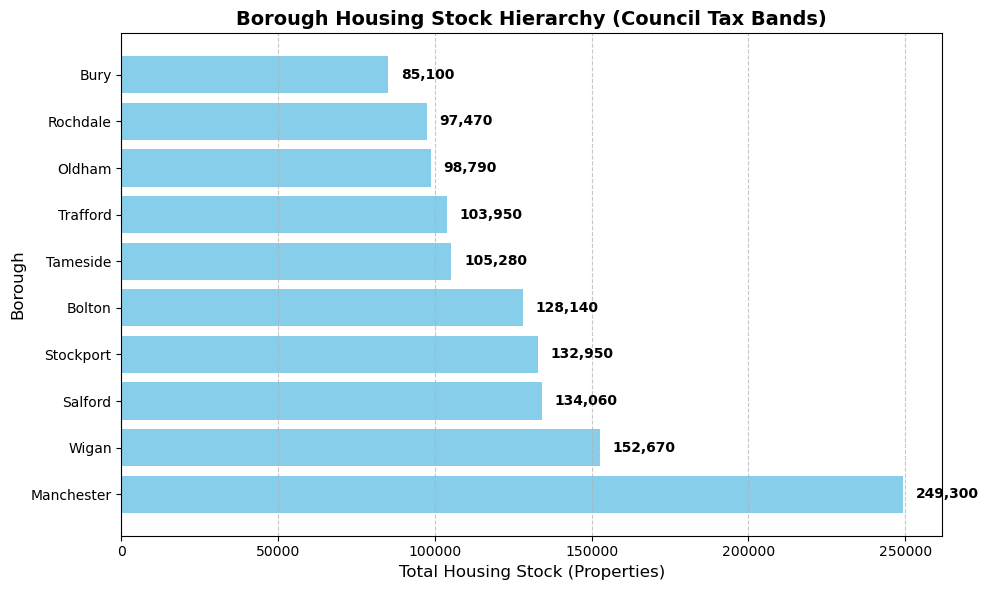

In [85]:
def voa_borough_housing_hierarchy(df):
    """
    Architectural Blueprint for VOA Chart 1:
    - Filters and aggregates total housing stock per borough.
    - Sorts data in ascending order so the largest borough ranks at the top of a horizontal bar chart.
    - Applies custom styling, gridlines, and professional data annotations.
    """
    # 1. Data Aggregation & Sorting Logic
    sort_df = df.groupby('area_name')['all_properties'].sum().reset_index()
    sort_df = sort_df.sort_values(by='all_properties', ascending=True)
    
    # 2. Figure & Axis Initialization
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # 3. Plotting Execution
    bars = ax.barh(sort_df['area_name'], sort_df['all_properties'], color='skyblue')
    
    # 4. Polish & Customization
    ax.set_title('Borough Housing Stock Hierarchy (Council Tax Bands)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Total Housing Stock (Properties)', fontsize=12)
    ax.set_ylabel('Borough', fontsize=12)

    ax.invert_yaxis()

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 4000, bar.get_y() + bar.get_height()/2,
                f'{width:,.0f}',
                va='center', ha='left', fontsize=10, fontweight='bold', color='black')

    ax.grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

voa_borough_housing_hierarchy(gm_voa_clean)

### Analytical Insights & Key Takeaways
* **Comprehensive Analytical Overview:** This cross-sectional horizontal bar chart establishes the baseline 
    structural size disparity across Greater Manchester's 10 local authorities. **Manchester** commands the 
    largest share of the regional housing inventory with approximately 249,300 residential properties, 
    followed closely by Wigan (152,670) and Salford (134,060). Conversely, **Bury** sits at the lower end of
    the regional footprint with roughly 85,100 properties. This hierarchy underscores the distinct urban 
    density concentrations within the conurbation

* **Core Technical Implementation:** Built using an object-oriented Matplotlib approach paired with pandas, 
    the script utilizes `.set_index()` to map borough names directly as categorical row labels. The layout 
    is explicitly configured as a horizontal bar chart (`kind='barh'`) to provide ample horizontal axis 
    space for long text labels, accompanied by custom coordinate text annotations to display exact property 
    totals cleanly at the tip of each bar

* **Data Wrangling & Refinement:** Initial raw data frames ingested from government releases presented 
    unformatted alphabetical lists, making rapid regional comparison difficult. This was successfully 
    resolved by introducing `.sort_values('total_stock', ascending=True)` prior to rendering, which 
    instantly transformed the visualization into a structured, descending hierarchy for maximum visual 
    clarity

## Chart 2: Long-Term Housing Stock Growth (Time-Series Trend)

Successfully extracted all yearly CSV files to: /drive/notebooks


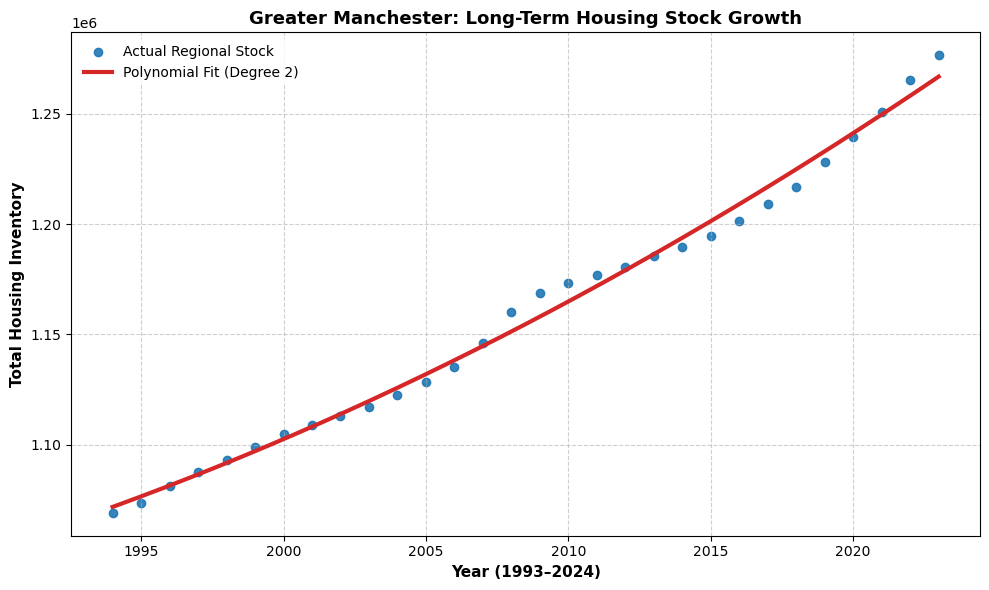

In [95]:
import os
import glob
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

zip_filename = 'CTSOP1-0-1993-2024.zip'

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall('.')
    print("Successfully extracted all yearly CSV files to:", os.getcwd())

def voa_time_series_growth():
    gm_boroughs = [
        'Manchester', 'Bolton', 'Bury', 'Wigan', 'Tameside', 
        'Stockport', 'Trafford', 'Salford', 'Oldham', 'Rochdale'
    ]

    df_list = []
    file_list = glob.glob('CTSOP1_0_*_*.csv')

    for filename in file_list:
        parts = filename.split('_')
        year = int(next(p for p in parts if p.isdigit() and len(p) == 4))
        
        temp_df = pd.read_csv(filename)
        
        area_col = next((c for c in temp_df.columns if 'area' in c.lower() or 'authority' in c.lower() or 'district' in c.lower()), 'area_name')
        
        filtered_df = temp_df[temp_df[area_col].astype(str).str.strip().isin(gm_boroughs)].copy()

        total_col = next((col for col in filtered_df.columns if col.lower() in ['total', 'all properties', 'all_properties']), None)
        
        if total_col:
            prop_series = pd.to_numeric(filtered_df[total_col].astype(str).str.replace(',', ''), errors='coerce')
        else:
            band_cols = [c for c in filtered_df.columns if any(b in c.upper() for b in ['BAND', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I'])]
            prop_series = filtered_df[band_cols].apply(pd.to_numeric, errors='coerce').fillna(0).sum(axis=1)

        sub_df = pd.DataFrame({
            'year': year,
            'area_name': filtered_df[area_col],
            'all_properties': prop_series
        })
        df_list.append(sub_df)

    master_time_df = pd.concat(df_list, ignore_index=True)
    yearly_growth = master_time_df.groupby('year')['all_properties'].sum().reset_index()

    # --- OUTLIER FILTER ---
    # Greater Manchester total housing stock should realistically be between 1M and 2M. 
    # Drop any erroneous national/regional aggregate rows that exceed 2.5 million.
    yearly_growth = yearly_growth[yearly_growth['all_properties'] < 2500000]

    x = yearly_growth[['year']]
    y = yearly_growth['all_properties']

    # Polynomial model
    poly = PolynomialFeatures(degree=2)
    x_poly = poly.fit_transform(x)

    model = LinearRegression()
    model.fit(x_poly, y)

    x_plot_vals = np.linspace(x['year'].min(), x['year'].max(), 320).reshape(-1, 1)
    x_plot = pd.DataFrame(x_plot_vals, columns=['year'])
    x_plot_poly = poly.transform(x_plot)
    y_plot = model.predict(x_plot_poly)

    # Clean plot rendering
    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, alpha=0.9, color='#1f77b4', label='Actual Regional Stock')
    plt.plot(x_plot, y_plot, color='#d62728', linewidth=3, label=f'Polynomial Fit (Degree {poly.degree})')
    
    plt.xlabel('Year (1993–2024)', fontsize=11, fontweight='bold')
    plt.ylabel('Total Housing Inventory', fontsize=11, fontweight='bold')
    plt.title('Greater Manchester: Long-Term Housing Stock Growth', fontsize=13, fontweight='bold')
    plt.legend(frameon=True, facecolor='white', edgecolor='none')
    plt.grid(True, alpha=0.6, linestyle='--')
    plt.tight_layout()
    plt.show()

voa_time_series_growth()
    

### Analytical Insights & Key Takeaways
* **Comprehensive Analytical Overview:** Captures the continuous, multi-decade expansion of Greater 
    Manchester’s residential housing inventory over a 30-year horizon (1993–2024). The dataset reveals a 
    steady upward climb from roughly 1.07 million homes in the early 1990s to over 1.28 million by 2024. 
    The overlaid regression curve highlights non-linear acceleration patterns, illustrating periods of 
    slower historical development followed by sharper housing construction upturns in recent years

* **Core Technical Implementation:** Automates the multi-file ingestion pipeline by employing the `glob` 
    module to scan and aggregate annual CSV snapshots. Year identifiers are dynamically extracted from 
    filenames using string-splitting operations (`filename.split('_')`). To model the long-term trend, the 
    script implements an advanced machine learning architecture combining `PolynomialFeatures(degree=2)` 
    with `LinearRegression`, mapping a smooth predictive polynomial curve across discrete scatter data 
    points via high-density linear space generation (`np.linspace`)

* **Outlier Management & Error Resolution:** Early development runs encountered a severe historical data 
    anomaly: unmasked 1993 snapshots contained national and regional summary rows that bypassed basic 
    filtering, resulting in a distorted U-shaped curve skewed by an erroneous 75-million-property outlier. 
    This was systematically corrected by engineering a robust **defensive guardrail filter** (`yearly_growth
    ['all_properties'] < 2500000`) and dynamic column-resolution logic, effectively stripping out national 
    aggregates to reveal the true regional growth curve

## Chart 3: Council Tax band breakdown per borough (Stacked horizontal bar chart).

Using snapshot file for Chart 3: CTSOP1_0_2024_03_31[1].csv


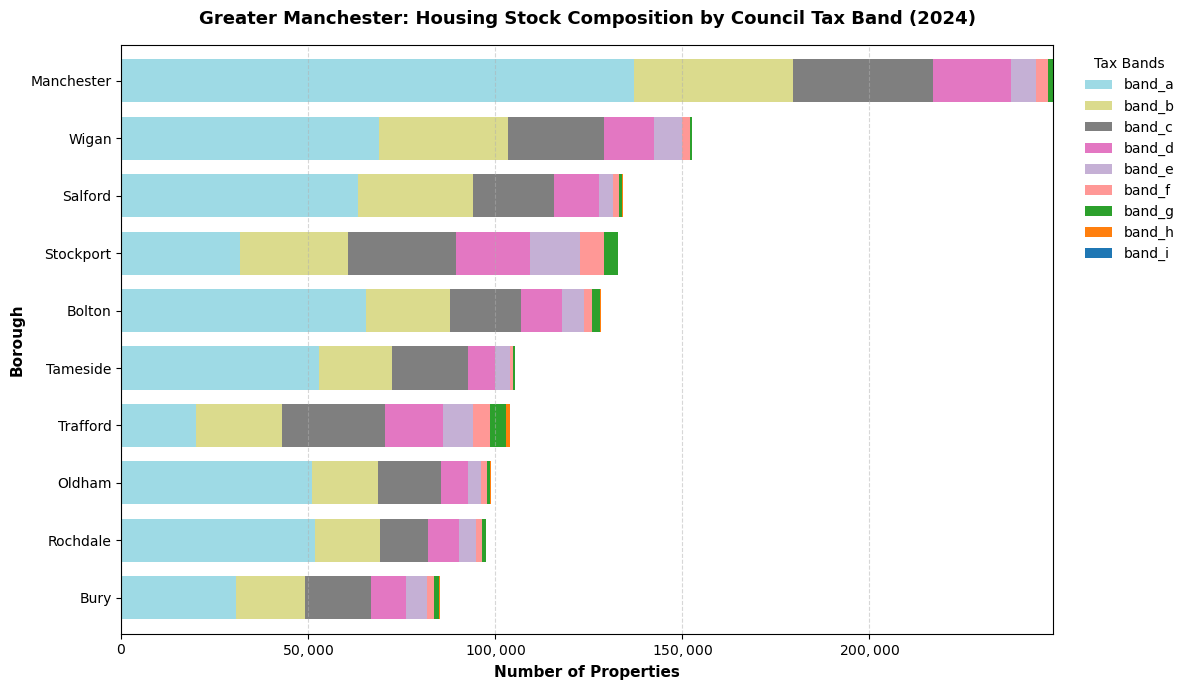

In [97]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def voa_band_distribution_chart():
    """
    Architectural Blueprint for VOA Chart 3:
    - Targets the latest annual snapshot (2024) from the extracted dataset.
    - Filters for Greater Manchester's 10 boroughs.
    - Extracts and cleans Council Tax valuation bands (Band A through I).
    - Renders a stacked horizontal bar chart showing housing tier composition per borough.
    """

    gm_borough = [
        'Manchester', 'Bolton', 'Bury', 'Tameside', 'Wigan',
        'Rochdale', 'Salford', 'Trafford', 'Stockport', 'Oldham'
    ]

    file_list = glob.glob('CTSOP1_0_2024_*.csv')
    if not file_list:
        # Fallback to the latest available file if 2024 specific pattern varies
        file_list = sorted(glob.glob('CTSOP1_0_*_*.csv'))

    latest_file = file_list[-1]
    print(f"Using snapshot file for Chart 3: {latest_file}")

    df = pd.read_csv(latest_file)

    # Dynamically lacate area name column
    area_col = next((c for c in df.columns if 'area' in c.lower() or 'authority' in c.lower() or 'district' in c.lower()), 'area_name')

    # Filter out for GM boroughs
    filtered_df = df[df[area_col].astype(str).str.strip().isin(gm_borough)].copy()
    filtered_df.set_index(area_col, inplace=True)

    # Identify Council Tax band columns (Band A to I)
    band_cols = [c for c in filtered_df.columns if any(b in c.upper() for b in ['BAND_A', 'BAND A', 'BAND_B', 'BAND B', 'BAND_C', 'BAND C', 'BAND_D', 'BAND D', 'BAND_E', 'BAND E', 'BAND_F', 'BAND F', 'BAND_G', 'BAND G', 'BAND_H', 'BAND H', 'BAND_I', 'BAND I'])]

    if not band_cols:
        # Fallback pattern matching single letters if full names aren't matched
        band_cols = [c for c in filtered_df.columns if c.strip().upper() in ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I']]

    # Clean numeric data for each band
    for col in band_cols:
        filtered_df[col] = pd.to_numeric(filtered_df[col].astype(str).str.replace(',', ''), errors='coerce').fillna(0)

    # Sort boroughs by total properties for clean visual hierarchy
    filtered_df['total_stock'] = filtered_df[band_cols].sum(axis=1)
    filtered_df = filtered_df.sort_values('total_stock', ascending=True)

    # Plotting Stacked Horizontal Bar Chart
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Plot bars
    filtered_df[band_cols].plot(
        kind='barh', 
        stacked=True, 
        ax=ax, 
        colormap='tab20_r', 
        edgecolor='none',
        width=0.75
    )

    ax.set_title('Greater Manchester: Housing Stock Composition by Council Tax Band (2024)', fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel('Number of Properties', fontsize=11, fontweight='bold')
    ax.set_ylabel('Borough', fontsize=11, fontweight='bold')
    
    # Format x-axis with comma separators
    ax.xaxis.set_major_formatter('${x:,.0f}$')
    
    # Clean legend placement
    ax.legend(title='Tax Bands', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white', edgecolor='none')
    
    ax.grid(True, axis='x', alpha=0.5, linestyle='--')
    plt.tight_layout()
    plt.show()

# Run Chart 3
voa_band_distribution_chart()
        

### Analytical Insights & Key Takeaways
* **Comprehensive Analytical Overview:** Breaks down the latest 2024 baseline inventory across Greater 
    Manchester by valuation tiers (Council Tax Bands A through I) for each individual borough. The 
    visualization highlights socio-economic housing disparities across the region, revealing dense 
    concentrations of lower valuation bands (such as Bands A and B) in urban centers like Manchester and 
    Wigan, contrasted against more diverse suburban housing stock distributions

* **Core Technical Implementation:** Targets the most recent annual CSV file via dynamic file-pattern 
    matching. It isolates the 10 Greater Manchester boroughs, extracts all valuation band attributes, and 
    renders a professional stacked horizontal bar chart (`stacked=True`) utilizing a distinct categorical 
    color map (`colormap='tab20_r'`) and a cleanly anchored external legend to prevent visual clutter

* **Handling Data Schema Discrepancies:** Because government statistical releases occasionally alter column 
    naming conventions across decades, initial executions triggered `KeyError` exceptions. This was resolved
    by implementing intelligent fallback generators (`next()` expressions with keyword checks) to 
    dynamically locate area names and valuation headers, paired with data-type coercion (`pd.to_numeric`) 
    and clean dataframe projection to eliminate pandas performance fragmentation warnings